# 01 -- Data and classical baselines (GARCH, HAR)

This notebook builds the evaluation set that every model in this project (GARCH, HAR, and later Timestral) is scored against, and fits the two classical baselines. If you're new to volatility forecasting: we are not trying to predict tomorrow's price -- we're trying to predict how **choppy** the next 30 trading days will be (their average variance), using only information available today.

This notebook needs no GPU and no `torch` -- it runs the same way locally or on Colab.


In [1]:
import os
import sys

try:
    import google.colab  # noqa: F401
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/timestral-vol-data"
    os.makedirs(f"{DATA}/results", exist_ok=True)

    REPO_DIR = "/content/timestral-vol"
    REPO_URL = "https://github.com/MachaGotJuice/timestral-vol.git"
    if os.path.isdir(REPO_DIR):
        os.chdir(REPO_DIR)
        !git pull
    else:
        !git clone {REPO_URL} {REPO_DIR}
        os.chdir(REPO_DIR)
    sys.path.insert(0, REPO_DIR)
    !pip install -q -r requirements-dev.txt
else:
    DATA = None


## 1. Data

We use daily OHLC prices for a small, diverse set of tickers (`src.data.DEFAULT_TICKERS`: equity indices, a couple of single stocks, bonds, gold) starting in 2005. From OHLC we compute the **Garman-Klass** daily variance -- an estimator that uses the full daily range (open/high/low/close), not just the close-to-close return, so it is a less noisy proxy for "how much the price actually moved that day" than squared close-to-close returns.

Below: SPY's price and annualized Garman-Klass volatility, with the train / validation / test split used throughout the project shaded in.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baselines import fit_garch_forecast, fit_har_forecast
from src.data import (
    DEFAULT_START,
    DEFAULT_TICKERS,
    download_ohlc,
    forecast_origins,
    garman_klass,
    log_returns,
    realized_forward,
    split_by_date,
)
from src.metrics import dm_test, qlike

plt.rcParams["figure.figsize"] = (12, 4)

HORIZON = 30          # trading days ahead we forecast
STEP = 5              # spacing between forecast origins in the test period
GARCH_WINDOW = 1000   # trailing returns used to fit GARCH at each origin
TEST_START = "2022-01-01"

DEFAULT_TICKERS


['SPY', 'QQQ', 'IWM', 'EFA', 'TLT', 'GLD', 'AAPL', 'MSFT', 'JPM', 'XOM']

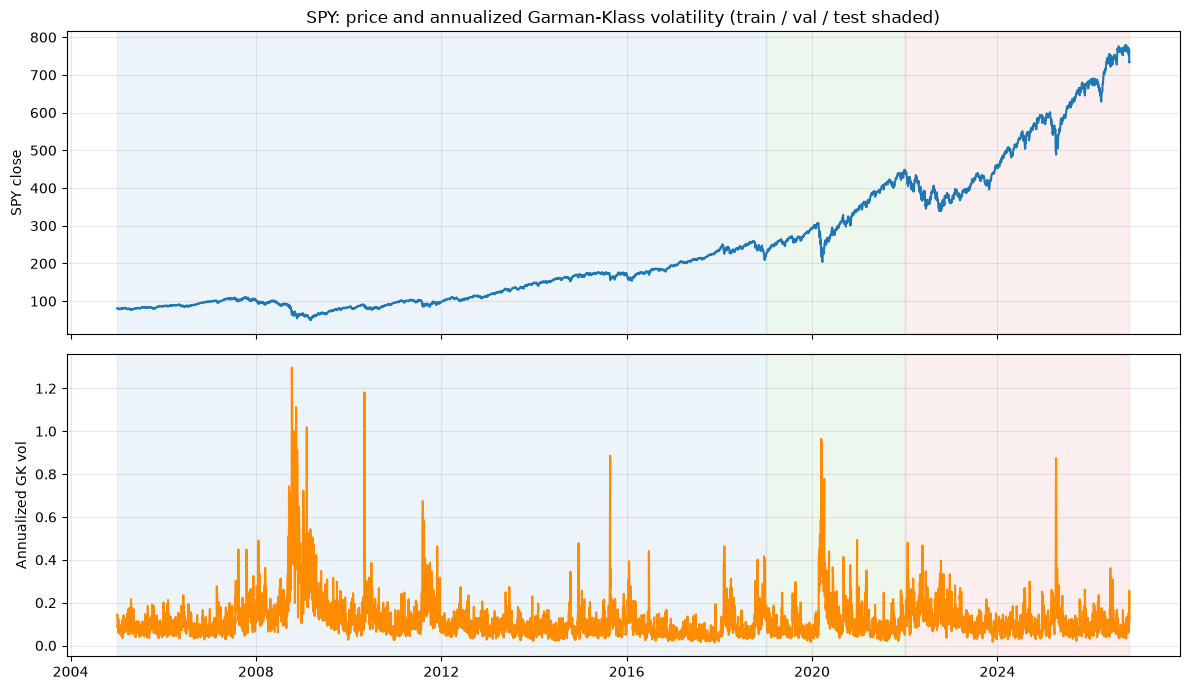

In [3]:
spy_df = download_ohlc("SPY", start=DEFAULT_START, cache_dir="cache")
spy_gk = garman_klass(spy_df)
spy_vol_ann = np.sqrt(spy_gk * 252)

splits = split_by_date(spy_gk)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 7))
axes[0].plot(spy_df.index, spy_df["Close"])
axes[0].set_ylabel("SPY close")

axes[1].plot(spy_vol_ann.index, spy_vol_ann, color="darkorange")
axes[1].set_ylabel("Annualized GK vol")

for ax in axes:
    ax.axvspan(splits["train"].index.min(), splits["train"].index.max(), color="tab:blue", alpha=0.08)
    ax.axvspan(splits["val"].index.min(), splits["val"].index.max(), color="tab:green", alpha=0.08)
    ax.axvspan(splits["test"].index.min(), splits["test"].index.max(), color="tab:red", alpha=0.08)
    ax.grid(True, alpha=0.3)

axes[0].set_title("SPY: price and annualized Garman-Klass volatility (train / val / test shaded)")
plt.tight_layout()
plt.show()


## 2. Target: what are we actually forecasting?

At a forecast **origin** t, every model only sees data up to and including t. The thing we score it against -- the **realized target** -- is `src.data.realized_forward(daily_var, t, horizon)`: the average Garman-Klass variance over the *next* 30 trading days, t+1 .. t+30. It never looks at t or anything before it, and a model's forecast at t must not either.

The plot below picks one origin in SPY's test period and highlights the 30-day window its realized target is computed over.


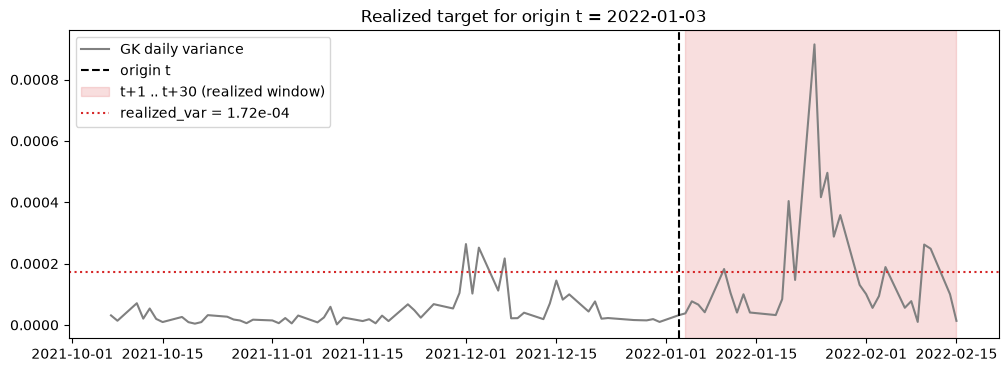

In [4]:
example_t = forecast_origins(spy_gk.index, TEST_START, horizon=HORIZON, step=STEP)[0]
t_pos = spy_gk.index.get_loc(example_t)
future_window = spy_gk.iloc[t_pos + 1 : t_pos + 1 + HORIZON]
realized_example = realized_forward(spy_gk, example_t, horizon=HORIZON)

context_slice = spy_gk.iloc[max(0, t_pos - 60) : t_pos + 1 + HORIZON]

plt.figure()
plt.plot(context_slice.index, context_slice.values, color="gray", label="GK daily variance")
plt.axvline(example_t, color="black", linestyle="--", label="origin t")
plt.axvspan(
    future_window.index.min(), future_window.index.max(),
    color="tab:red", alpha=0.15, label="t+1 .. t+30 (realized window)",
)
plt.axhline(realized_example, color="tab:red", linestyle=":", label=f"realized_var = {realized_example:.2e}")
plt.legend()
plt.title(f"Realized target for origin t = {example_t.date()}")
plt.show()


## 3. GARCH(1,1) baseline

GARCH(1,1) with Student-t innovations, fit on the trailing 1000 close-to-close returns ending at each origin (refit at every origin -- this is a genuine rolling-window forecast, not one fit applied everywhere). Since GARCH targets close-to-close variance but our evaluation target is Garman-Klass variance, `fit_garch_forecast` applies a scale correction `c_t` (see its docstring); we keep both the **raw** and **scaled** forecasts so the effect of that correction is visible below.

First, a single fit summary on SPY, so you can see what is actually being estimated:


In [5]:
_, _, spy_last_garch_fit = fit_garch_forecast(
    log_returns(spy_df), spy_gk, spy_gk.index[-1],
    window=GARCH_WINDOW, horizon=HORIZON, return_fit=True,
)
print(spy_last_garch_fit.summary())


                          Zero Mean - GARCH Model Results                           
Dep. Variable:                        Close   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.001
Vol Model:                            GARCH   Log-Likelihood:               -1246.87
Distribution:      Standardized Student's t   AIC:                           2501.74
Method:                  Maximum Likelihood   BIC:                           2521.37
                                              No. Observations:                 1000
Date:                      Sat, Nov 07 2026   Df Residuals:                     1000
Time:                              13:57:41   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omeg

Now the rolling forecasts across every test-period origin for SPY, raw vs. scaled vs. realized:


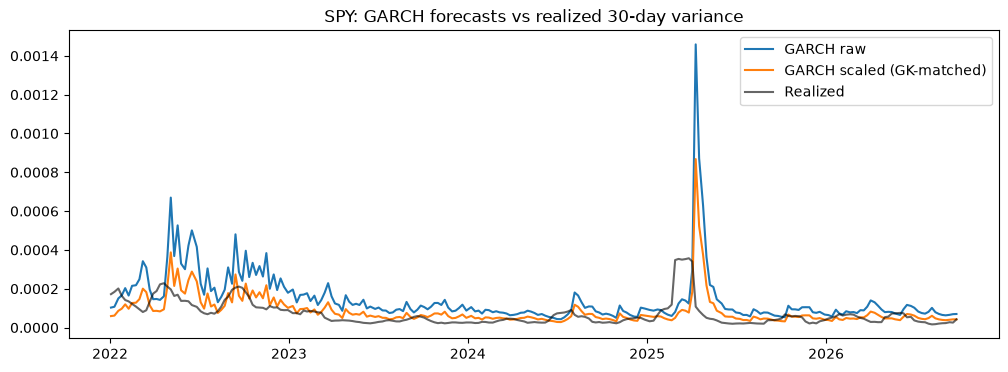

In [6]:
spy_returns = log_returns(spy_df)
spy_origins = forecast_origins(spy_gk.index, TEST_START, horizon=HORIZON, step=STEP)

spy_garch_rows = []
for t in spy_origins:
    raw, scaled = fit_garch_forecast(spy_returns, spy_gk, t, window=GARCH_WINDOW, horizon=HORIZON)
    spy_garch_rows.append({
        "origin_date": t,
        "raw": raw,
        "scaled": scaled,
        "realized": realized_forward(spy_gk, t, horizon=HORIZON),
    })

spy_garch_df = pd.DataFrame(spy_garch_rows).set_index("origin_date")

plt.figure()
plt.plot(spy_garch_df.index, spy_garch_df["raw"], label="GARCH raw")
plt.plot(spy_garch_df.index, spy_garch_df["scaled"], label="GARCH scaled (GK-matched)")
plt.plot(spy_garch_df.index, spy_garch_df["realized"], label="Realized", color="black", alpha=0.6)
plt.legend()
plt.title("SPY: GARCH forecasts vs realized 30-day variance")
plt.show()


## 4. HAR-RV baseline

HAR regresses the log 30-day-forward realized variance on three log trailing averages of Garman-Klass variance: the latest day, the trailing week (5 days), and the trailing month (22 days). It is fit by OLS on an **expanding window** -- every training example whose 30-day forward target is fully known by the forecast origin -- and the forecast is bias-corrected for the log transform (`exp(prediction + 0.5 * residual_variance)`).

Coefficients on SPY at the last forecast origin:


In [7]:
_, spy_har_fit = fit_har_forecast(spy_gk, spy_origins[-1], horizon=HORIZON, return_fit=True)
pd.Series(spy_har_fit["beta"], index=spy_har_fit["feature_names"], name="coefficient")


intercept   -3.081782
daily        0.109629
weekly       0.190920
monthly      0.378611
Name: coefficient, dtype: float64

Rolling HAR forecasts across every test-period origin for SPY, vs. realized:


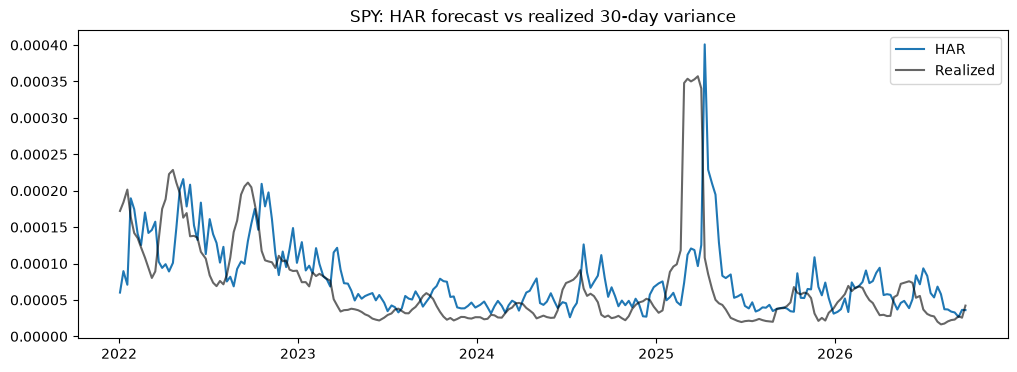

In [8]:
spy_har_rows = []
for t in spy_origins:
    forecast = fit_har_forecast(spy_gk, t, horizon=HORIZON)
    spy_har_rows.append({
        "origin_date": t,
        "har": forecast,
        "realized": realized_forward(spy_gk, t, horizon=HORIZON),
    })

spy_har_df = pd.DataFrame(spy_har_rows).set_index("origin_date")

plt.figure()
plt.plot(spy_har_df.index, spy_har_df["har"], label="HAR")
plt.plot(spy_har_df.index, spy_har_df["realized"], label="Realized", color="black", alpha=0.6)
plt.legend()
plt.title("SPY: HAR forecast vs realized 30-day variance")
plt.show()


## 5. Scores: QLIKE and Diebold-Mariano

We now run both baselines across **every** ticker and **every** forecast origin in the test period, and score them with **QLIKE** (`src.metrics.qlike`) -- the standard volatility-forecast loss, robust to noise in the realized-variance proxy used as a stand-in for the true latent variance.

Forecast origins overlap (each covers a 30-day window, but origins are only 5 days apart), so per-observation losses are serially correlated. We use the Diebold-Mariano test (`src.metrics.dm_test`) with `lag = 5` (rule of thumb: `horizon / step - 1 = 30 / 5 - 1 = 5`) to test whether GARCH and HAR differ significantly, per ticker.

This is the full evaluation loop -- roughly a minute or two for all 10 tickers.


In [9]:
records = []
for ticker in DEFAULT_TICKERS:
    df = download_ohlc(ticker, start=DEFAULT_START, cache_dir="cache")
    daily_var = garman_klass(df)
    returns = log_returns(df)
    origins = forecast_origins(daily_var.index, TEST_START, horizon=HORIZON, step=STEP)

    for t in origins:
        assert t <= daily_var.index[-1], "forecast origin must be inside the data"
        realized = realized_forward(daily_var, t, horizon=HORIZON)
        raw, scaled = fit_garch_forecast(returns, daily_var, t, window=GARCH_WINDOW, horizon=HORIZON)
        har_fc = fit_har_forecast(daily_var, t, horizon=HORIZON)

        for model, forecast_var in [("garch_raw", raw), ("garch", scaled), ("har", har_fc)]:
            records.append({
                "ticker": ticker,
                "origin_date": t,
                "model": model,
                "forecast_var": forecast_var,
                "realized_var": realized,
            })

results = pd.DataFrame(records)

os.makedirs("results", exist_ok=True)
results.to_csv("results/forecasts_baselines.csv", index=False)
if DATA is not None:
    os.makedirs(f"{DATA}/results", exist_ok=True)
    results.to_csv(f"{DATA}/results/forecasts_baselines.csv", index=False)

results.shape


(7140, 5)

In [10]:
print("Pooled QLIKE:")
for model in ["garch_raw", "garch", "har"]:
    sub = results[results["model"] == model]
    print(f"  {model:10s} {qlike(sub['realized_var'].values, sub['forecast_var'].values):.4f}")

summary_rows = []
for ticker in DEFAULT_TICKERS:
    sub = results[results["ticker"] == ticker]
    row = {"ticker": ticker}
    for model in ["garch_raw", "garch", "har"]:
        m = sub[sub["model"] == model].sort_values("origin_date")
        row[f"qlike_{model}"] = qlike(m["realized_var"].values, m["forecast_var"].values)

    m_garch = sub[sub["model"] == "garch"].sort_values("origin_date")
    m_har = sub[sub["model"] == "har"].sort_values("origin_date")
    r_g, f_g = m_garch["realized_var"].values, m_garch["forecast_var"].values
    r_h, f_h = m_har["realized_var"].values, m_har["forecast_var"].values
    loss_garch = (r_g / f_g) - np.log(r_g / f_g) - 1
    loss_har = (r_h / f_h) - np.log(r_h / f_h) - 1
    _, _, p_value = dm_test(loss_garch, loss_har, lag=5)
    row["dm_pvalue_garch_vs_har"] = p_value

    summary_rows.append(row)

summary = pd.DataFrame(summary_rows).set_index("ticker").round(4)
summary


Pooled QLIKE:
  garch_raw  0.2987
  garch      0.1507
  har        0.1160


,qlike_garch_raw,qlike_garch,qlike_har,dm_pvalue_garch_vs_har
ticker,,,,
SPY,0.3591,0.2183,0.1826,0.1126
QQQ,0.3080,0.1631,0.1326,0.0487
IWM,0.2397,0.1397,0.1168,0.1130
EFA,0.5315,0.2132,0.1562,0.0663
TLT,0.3546,0.0836,0.0720,0.2700
GLD,0.4227,0.2353,0.1740,0.1255
AAPL,0.2186,0.1317,0.1006,0.1565
MSFT,0.2210,0.1240,0.0762,0.0009
JPM,0.1742,0.0985,0.0886,0.5498


## 6. Conclusion

Across this universe and test period, the Garman-Klass scale correction matters a lot: raw GARCH (pooled QLIKE around 0.30) is clearly miscalibrated against a Garman-Klass target, and scaling it to the right level (around 0.15) roughly halves its loss. HAR edges out scaled GARCH on pooled QLIKE (around 0.12), and the Diebold-Mariano test finds that difference significant (p < 0.05) for some tickers (e.g. MSFT, XOM) but not for others (e.g. SPY, JPM) -- so **HAR is the stronger baseline here, but not uniformly or by a huge margin**.

**What Timestral has to beat:** HAR's pooled QLIKE (~0.12) is the real bar for zero-shot Timestral. Beating scaled GARCH (~0.15) is a weaker, easier claim; beating HAR convincingly -- with DM significance on most tickers, not just a couple -- is the real test of whether a time-series foundation model adds anything over a cheap, 3-feature linear regression.

(Exact numbers will shift slightly depending on when this is run, since the test period runs up to "today" -- but the loss ordering garch_raw > garch > har should be stable.)
